# Data over time

Lines (with direct end labels), splines, steps, areas, stacked areas and streamgraphs, rankings over time, financial OHLC/candlesticks, Gantt schedules and barcode event plots.

In [1]:
import warnings
warnings.filterwarnings("ignore", category=UserWarning)
import pandas as pd
import pychartist as pc
import plotly.io as pio
pio.renderers.default = "plotly_mimetype+notebook_connected"   # renders in JupyterLab/VS Code/Colab; plotly.js from CDN

In [2]:
stocks = pc.datasets.load('stocks'); flights = pc.datasets.load('flights')
unemp = pc.datasets.load('unemployment_industries'); aapl = pc.datasets.load('apple_stock')

In [3]:
pc.line(stocks, 'date', 'price', 'symbol', backend='plotly', title='Hover for a unified tooltip')

<Chart kind='line' backend='plotly' theme='pychartist'>

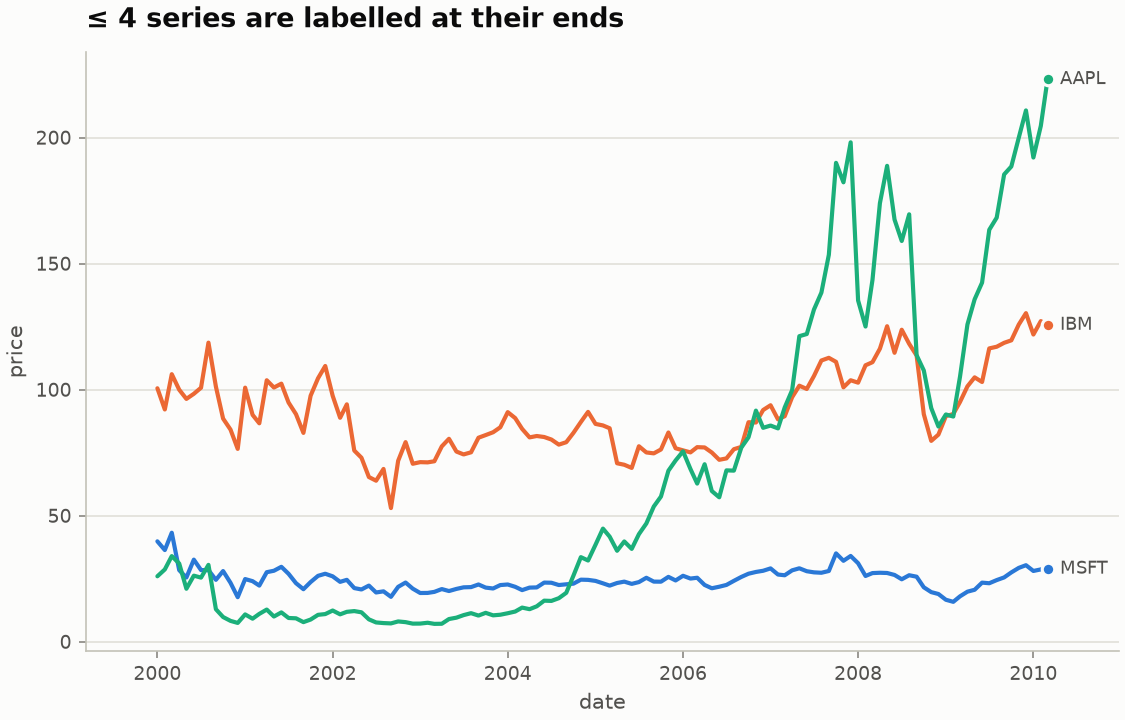

In [4]:
pc.line(stocks[stocks.symbol.isin(['AAPL', 'MSFT', 'IBM'])], 'date', 'price', 'symbol',
        title='≤ 4 series are labelled at their ends')

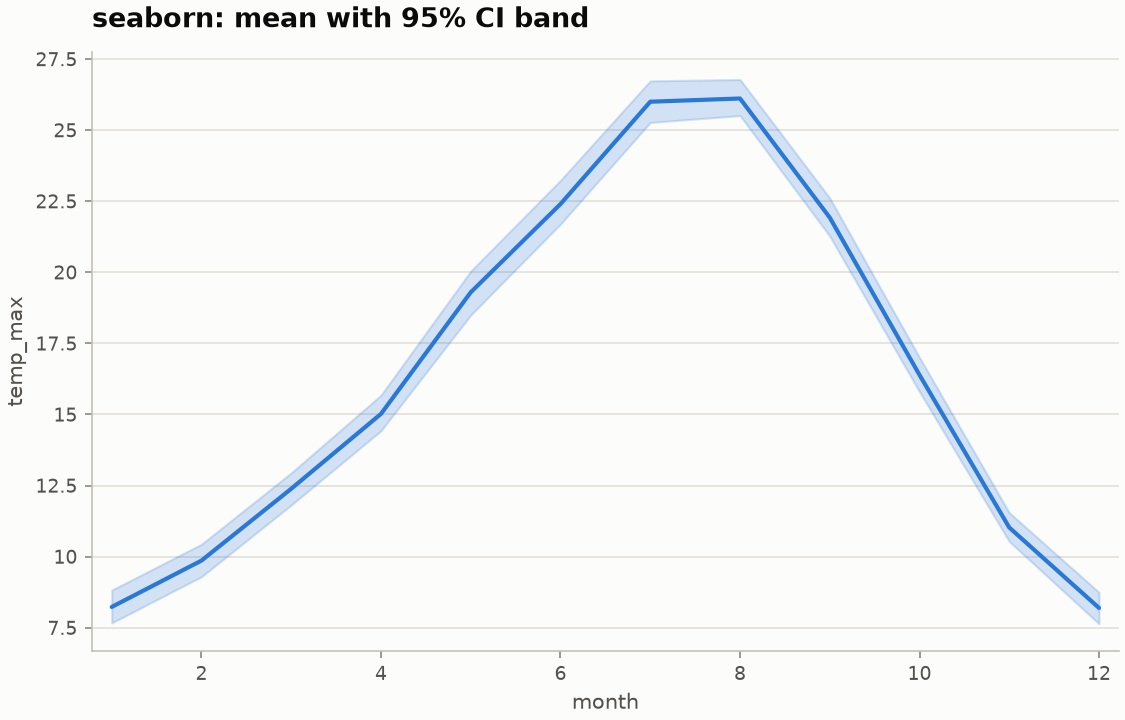

In [5]:
sea = pc.datasets.load('seattle_weather')
pc.line(sea.assign(month=sea.date.dt.month), 'month', 'temp_max', backend='seaborn',
        title='seaborn: mean with 95% CI band')

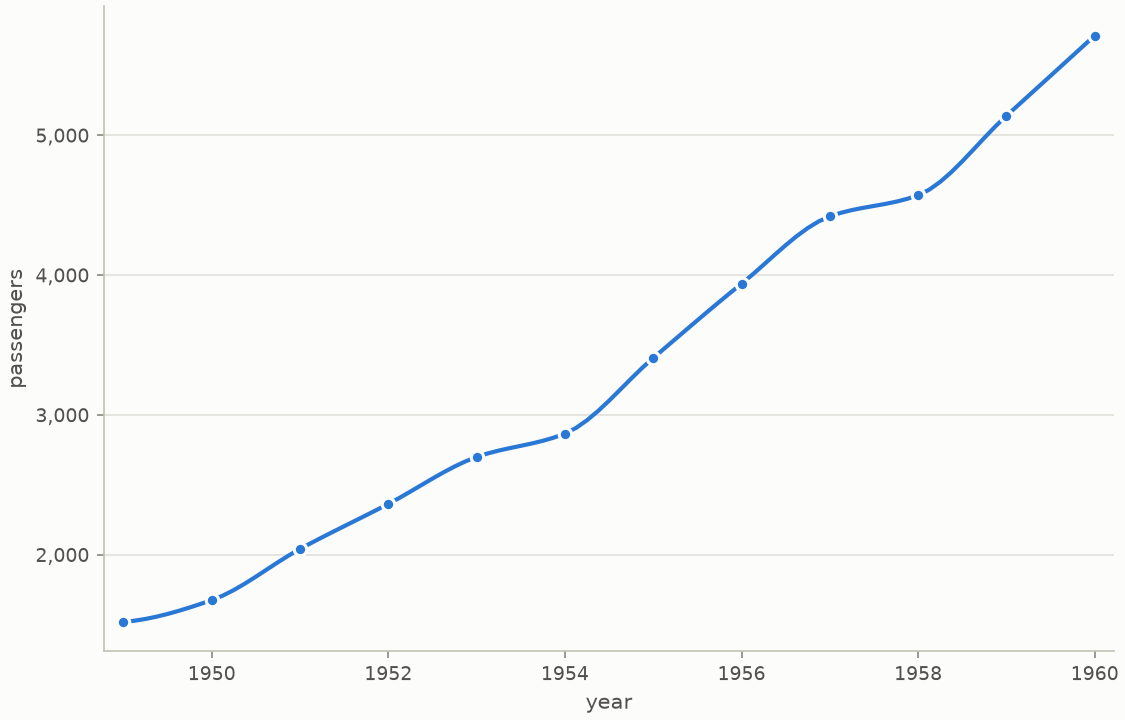

In [6]:
pc.spline(flights.groupby('year', as_index=False)['passengers'].sum(), 'year', 'passengers')

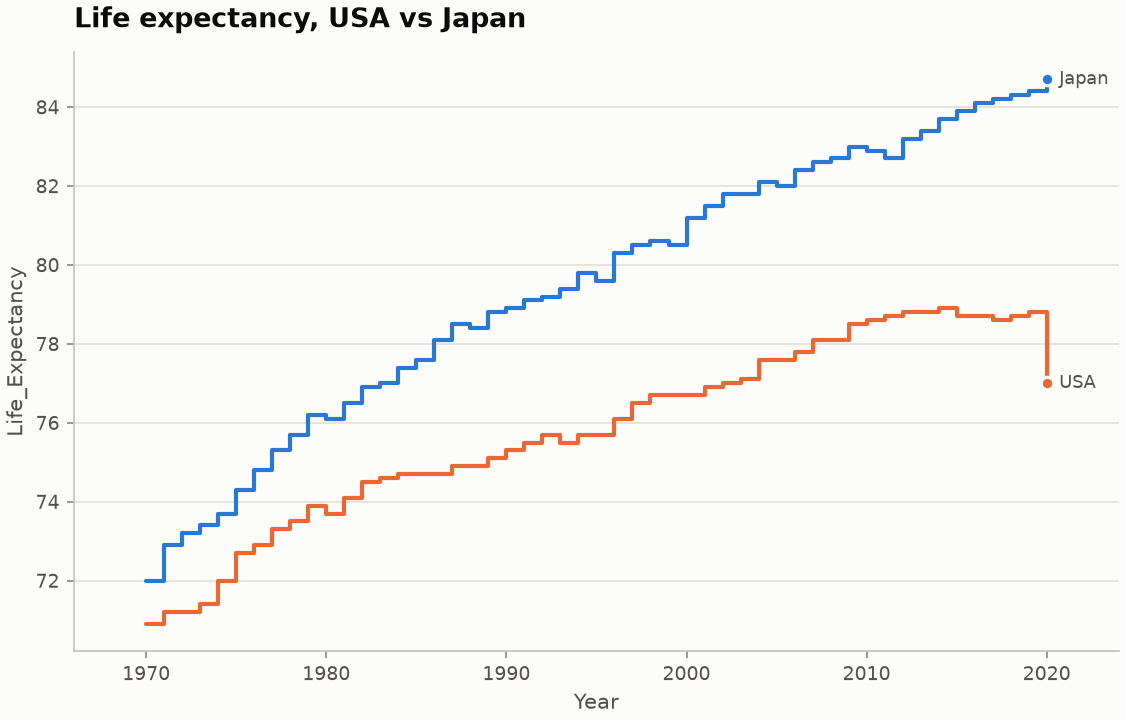

In [7]:
pc.examples.demo('step_line')

## Composition over time
More than 8 series? Fold the small ones into *Other* to keep colours distinguishable.

In [8]:
top = pc.fold_other(unemp, 'series', 'count', n=6)
pc.stacked_area(top, 'date', 'count', 'series', backend='plotly')

<Chart kind='stacked_area' backend='plotly' theme='pychartist'>

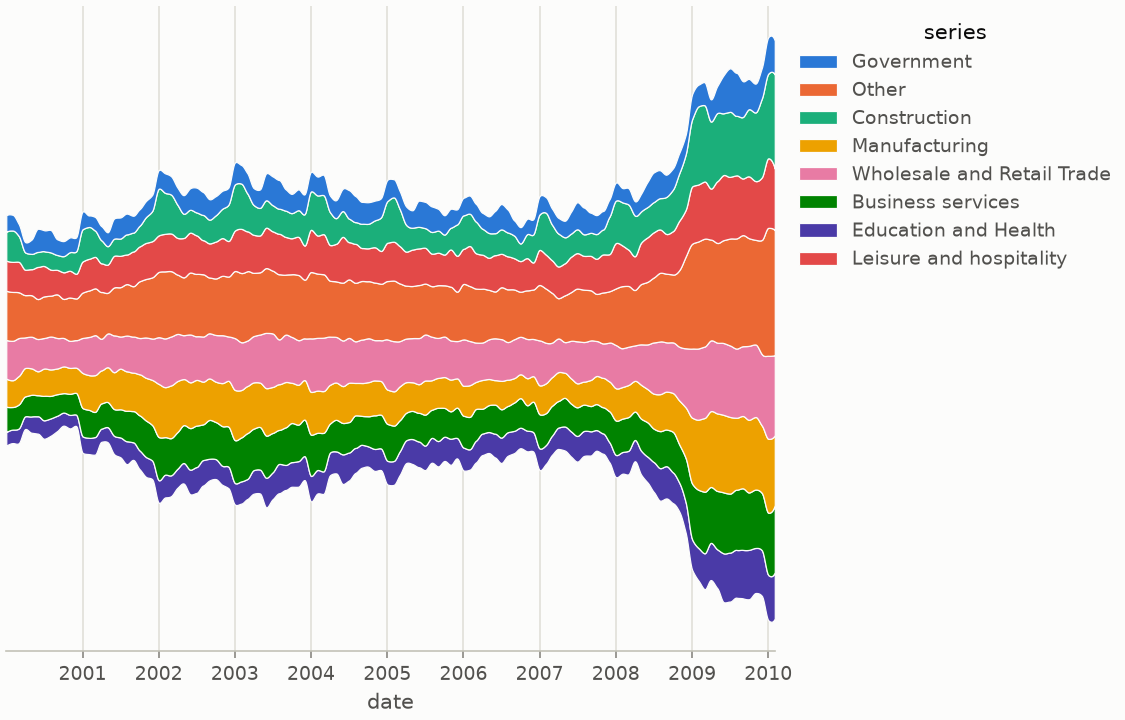

In [9]:
pc.streamgraph(pc.fold_other(unemp, 'series', 'count', n=7), 'date', 'count', 'series')

## Rankings

In [10]:
pc.examples.demo('bump', backend='plotly')

<Chart kind='bump' backend='plotly' theme='pychartist'>

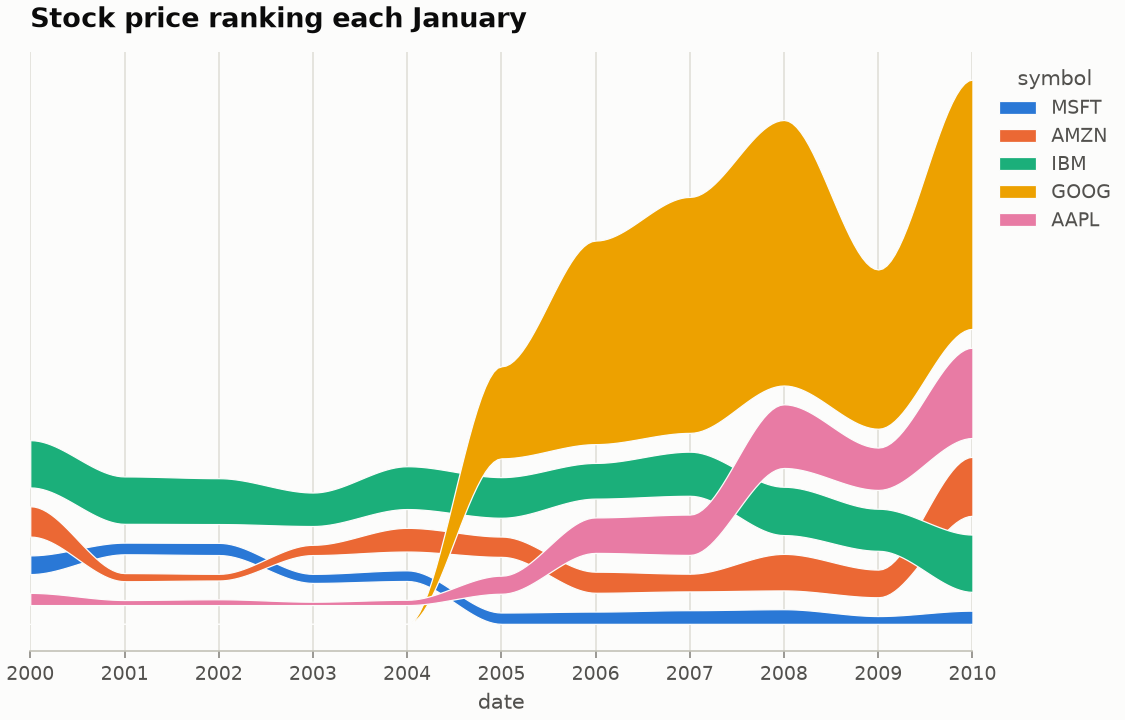

In [11]:
pc.examples.demo('bump_area')

## Finance

In [12]:
pc.candlestick(aapl.tail(90), 'Date', 'AAPL.Open', 'AAPL.High', 'AAPL.Low', 'AAPL.Close', backend='plotly')

<Chart kind='candlestick' backend='plotly' theme='pychartist'>

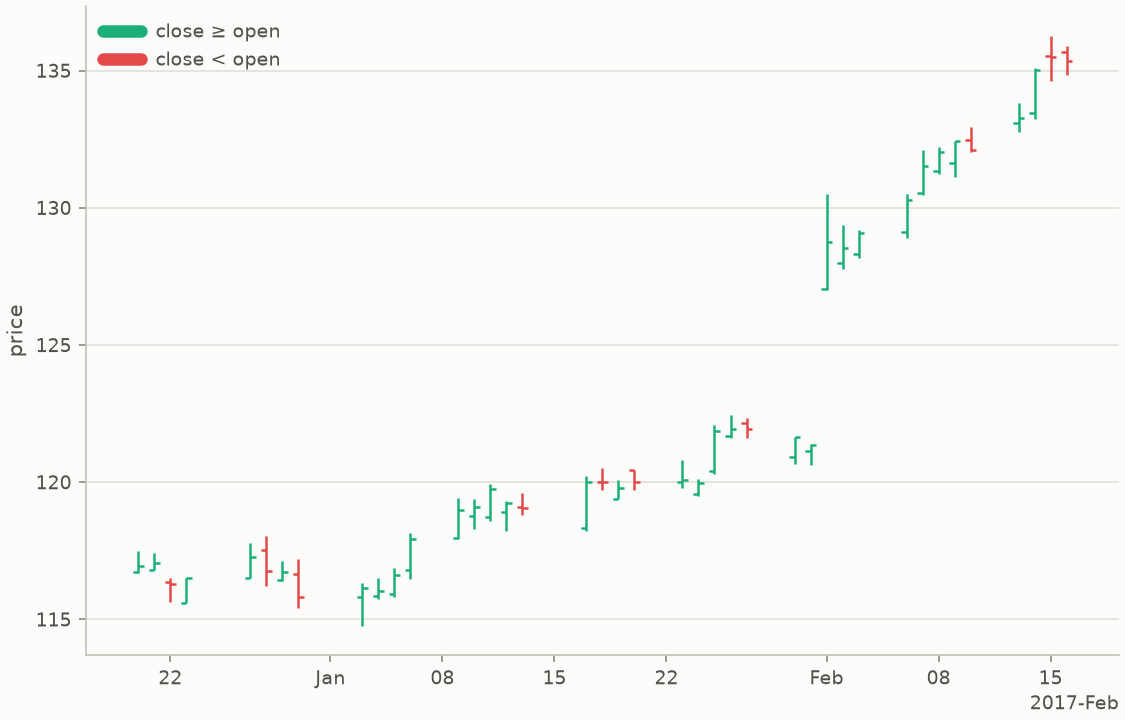

In [13]:
pc.ohlc(aapl.tail(40), 'Date', 'AAPL.Open', 'AAPL.High', 'AAPL.Low', 'AAPL.Close')

## Schedules and events

In [14]:
pc.examples.demo('gantt', backend='plotly')

<Chart kind='gantt' backend='plotly' theme='pychartist'>

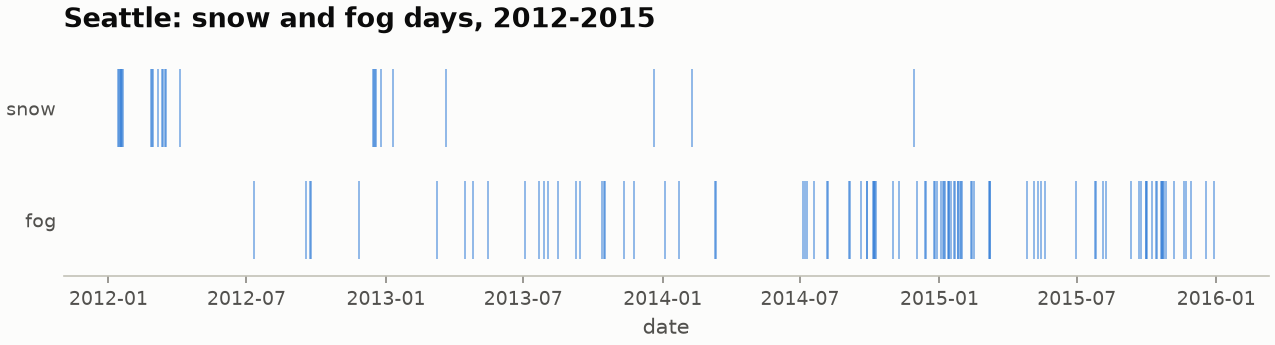

In [15]:
pc.examples.demo('barcode')